In [ ]:
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

#k_means
def Train(nb_classe, X):
    indices = np.random.choice(len(X), nb_classe, replace=False)
    Y = X[indices].copy()
    dic = {i: [] for i in range(nb_classe)}
    for it in range(10000000000000):  # condition d'arret d'urgence
        for x in X:
            dist = float("Inf")
            for i in range(nb_classe):
                sample_dist = np.linalg.norm(x-Y[i])#distance euclidienne
                if sample_dist < dist :
                    dist = sample_dist
                    cluster_index = i
            dic[cluster_index].append(x)
        # barycentre
        Y_updt = np.copy(Y)
        for i in range(len(Y)):
            Y_updt[i] = np.mean(dic[i], axis=0)
        if np.linalg.norm(Y - Y_updt) < 1e-5:
            print("has converged")
            break;
        else:
            Y = Y_updt
            dic = {i: [] for i in range(nb_classe)}
    return Y

def Evaluate(x, clusters):
    dist_min = float("Inf")
    cluster = -1
    for index, y in enumerate(clusters) :
        dist = np.linalg.norm(y-x)
        if dist<dist_min :
            dist_min = dist
            cluster = index
    return cluster

def PrepareDataForClassification(trainingDataFolderPath, testDataFolderPath):
    return (PrepareFolderForClassification(trainingDataFolderPath), PrepareFolderForClassification(testDataFolderPath))

def PrepareFolderForClassification(folderPath):
    dataFolder = Path(folderPath)
    dataSet = []
    for img_path in sorted(dataFolder.glob("*png")):
        data = PrepareData(img_path)
        dataSet.append(data)
    return np.array(dataSet);

def PrepareData(file):
    img = np.array(Image.open(file))
    hist_r = np.histogram(img[:, :, 0].ravel(), bins=256, range=(0, 256), density = True)[0]
    hist_g = np.histogram(img[:, :, 1].ravel(), bins=256, range=(0, 256), density = True)[0]
    hist_b = np.histogram(img[:, :, 2].ravel(), bins=256, range=(0, 256), density = True)[0]
    data = np.concatenate([hist_r, hist_g, hist_b])
    return data

def PlotClassHisto(class_name, clusters):
    classes = ["A", "B", "C", "D", "E", "F", "G", "H"]
    histo = {}
    for img_path in sorted(Path("Data/Classification/Test").glob(class_name + "*.png")):
        group = classes[Evaluate(PrepareData(img_path), clusters)]
        if group in histo:
            histo[group] += 1
        else :
            histo[group] = 1

    plt.bar(histo.keys(), histo.values())
    for x, y in histo.items():
        plt.text(x, y + 0.1, str(y), ha="center", va="bottom")

    plt.xlabel("Cluster")
    plt.ylabel("Nombre d'images")
    plt.title("Répartition des images de la classe "+class_name+" par cluster")
    plt.xticks(list(histo.keys()))
    plt.show()

In [53]:
trainingData, testData = PrepareDataForClassification("Data/Classification/Training", "Data/Classification/Test")
clusters = Train(8, trainingData)
print(clusters)

has converged
[[0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 1.97505951e-03 7.03620911e-03 ... 2.28881836e-05
  0.00000000e+00 1.04904175e-05]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [2.63328552e-02 1.47533417e-02 1.54056549e-02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


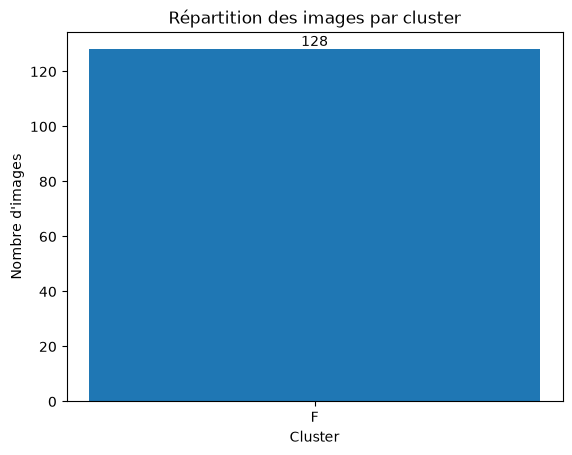

In [54]:
PlotClassHisto("alien", clusters)

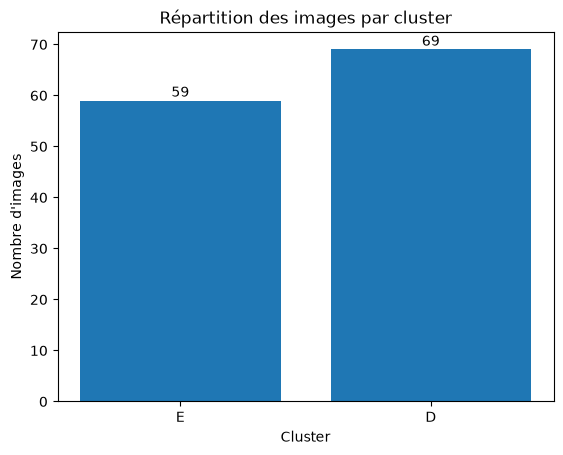

In [55]:
PlotClassHisto("apples", clusters)

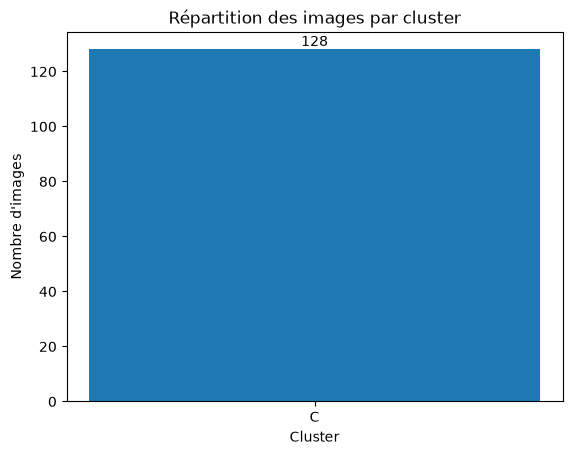

In [56]:
PlotClassHisto("brick", clusters)

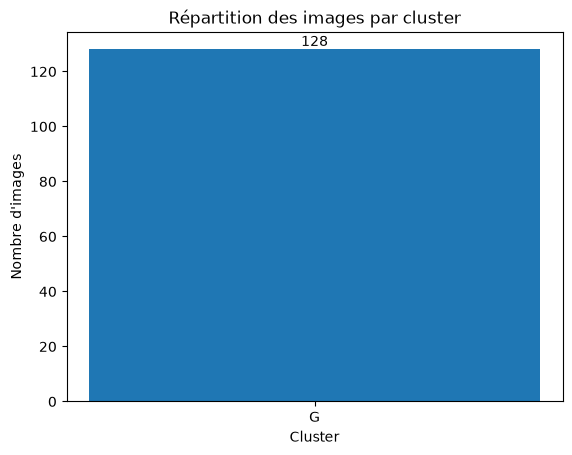

In [57]:
PlotClassHisto("grill", clusters)

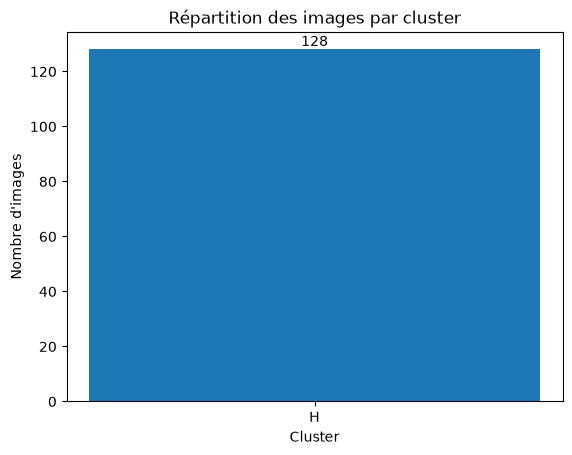

In [58]:
PlotClassHisto("red_fruits", clusters)

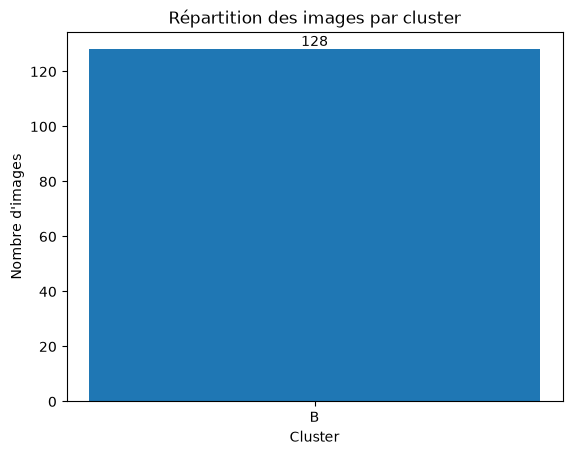

In [59]:
PlotClassHisto("rock", clusters)

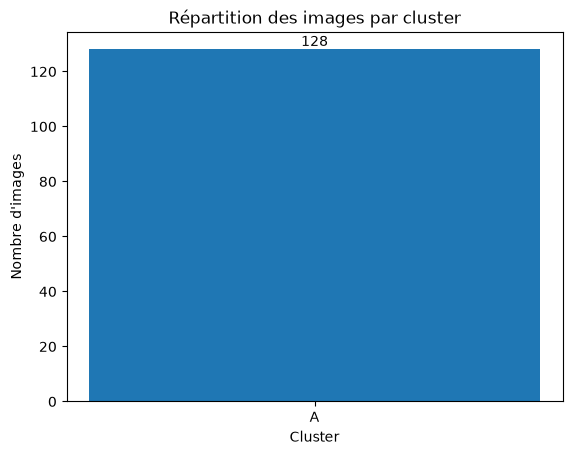

In [60]:
PlotClassHisto("sand", clusters)

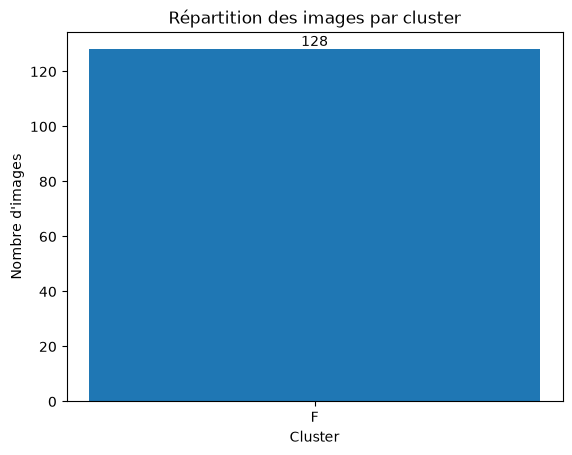

In [61]:
PlotClassHisto("wicker", clusters)